# Exploración del flujo neto por estación para P2 — MiBici

**Proyecto:** TC5061 · Equipo 52 · Pregunta P2 (clasificación)
**Autor:** Roberto Robles · **Rama:** `feature/p2-riesgo-estaciones`
**Antecedentes:** `1.0-rr-p2-exploracion-datos.ipynb` (inventario y tendencias) y `1.1-rr-p2-exploracion-estaciones.ipynb` (estaciones y capacidad).

**Propósito.** Obtener la evidencia para definir la etiqueta de P2. MiBici no publica cuántas bicicletas hay en cada estación, así que el riesgo se aproxima con el **flujo neto**: llegadas menos salidas de bicicletas en un periodo de tiempo, comparado con la capacidad de la estación.

**Debemos determinar:**
1. Cuánto se acumula el desbalance de una estación si cada hora se revisan las próximas N horas (N = 1 a 8, en una ventana que avanza de hora en hora), para elegir con cuántas horas de anticipación conviene revisar cada estación.
2. Qué umbral de riesgo, relativo a la capacidad, equilibra el servicio al cliente (no dejar pasar riesgos) con el costo de operación (no generar alertas innecesarias), con un balance de clases adecuado para entrenar.
3. En qué estaciones y a qué hora falla con más frecuencia el servicio al cliente (sin bicicletas o sin anclajes libres).

**Ventana de datos:** Post-Covid, del 9 de mayo de 2023 al 30 de septiembre de 2026 (etapa estable según el notebook 1.0).

**Estaciones excluidas (propuesta pendiente de acuerdo del equipo):** las de capacidad 0 y las de nombre «ex-» (notebook 1.1). Las 3 estaciones que no están en la nomenclatura quedan fuera porque no tienen capacidad.

**Viajes de menos de 1 minuto (acuerdo del equipo):** se excluyen al leer los datos (celda de lectura). No son viajes reales: la mayoría sale y regresa a la misma estación porque la bicicleta se devuelve de inmediato.

**Datos personales.** Solo se leen las columnas de fechas y estaciones; no se leen las de usuario, género ni año de nacimiento.

In [1]:
# Objetivo: preparar el entorno del notebook y fijar la ventana de datos.
# Las rutas salen de config.py; las fechas de la ventana se escriben aquí mientras el equipo las integra en config.py.
# Resultado esperado: número de archivos mensuales dentro de la ventana Post-Covid.

%load_ext autoreload
%autoreload 2

import sys
from pathlib import Path

import pandas as pd

sys.path.insert(0, str(Path.cwd().parent))  # raíz del proyecto, para importar el módulo
from equipo52_module.config import RAW_DATA_DIR

INICIO_VENTANA = pd.Timestamp("2023-05-09")  # fin de la emergencia sanitaria (decreto DOF)
FIN_VENTANA = pd.Timestamp("2026-10-01")     # exclusivo: incluye hasta el 30 de septiembre de 2026


def archivo_en_ventana(ruta):
    """Indica si el mes del archivo cae, aunque sea en parte, dentro de la ventana."""
    anio, mes = ruta.stem.split("_")[2:4]
    inicio_mes = pd.Timestamp(int(anio), int(mes[:2]), 1)
    return INICIO_VENTANA.replace(day=1) <= inicio_mes < FIN_VENTANA


archivos_ventana = [ruta for ruta in sorted(RAW_DATA_DIR.glob("datos_abiertos_*.csv")) if archivo_en_ventana(ruta)]
print(f"Archivos en la ventana: {len(archivos_ventana)} ({archivos_ventana[0].name} a {archivos_ventana[-1].name})")

2026-10-15 18:23:20.640 | INFO     | equipo52_module.config:<module>:11 - PROJ_ROOT path is: /Users/Roberto/Proyectos/equipo52_proyecto_mibici


Archivos en la ventana: 41 (datos_abiertos_2023_05.csv a datos_abiertos_2026_09.csv)


In [2]:
# Objetivo: leer los viajes de la ventana con sus fechas de inicio y fin y sus estaciones (posiciones 4 a 7).
# Las fechas vienen en dos formatos (notebook 1.0): AAAA-MM-DD HH:MM:SS y DD/MM/AAAA H:MM. Se prueba el primero
# y, donde no aplica, el segundo, indicando que el día va primero.
# Regla del equipo: se excluyen los viajes de menos de 1 minuto. No son viajes reales: casi todos salen y regresan a
# la misma estación (la bicicleta se devuelve de inmediato). Se cuentan antes de quitarlos.
# Resultado esperado: número de viajes leídos, fechas que no se pudieron convertir (debe ser 0), rango de fechas,
# viajes de menos de 1 minuto excluidos y resumen de la duración de los viajes analizados en minutos.

DURACION_MINIMA_SEGUNDOS = 60  # acuerdo del equipo


def convertir_fechas(texto):
    """Convierte texto a fecha probando los dos formatos encontrados en los archivos."""
    con_guiones = pd.to_datetime(texto, format="%Y-%m-%d %H:%M:%S", errors="coerce")
    con_diagonales = pd.to_datetime(texto, format="%d/%m/%Y %H:%M", errors="coerce")
    return con_guiones.fillna(con_diagonales)


def leer_viajes(ruta):
    """Lee fechas y estaciones de un archivo mensual, sin columnas personales."""
    datos = pd.read_csv(ruta, usecols=[4, 5, 6, 7], dtype="string", encoding="latin-1")
    datos.columns = ["inicio", "fin", "origen_id", "destino_id"]
    return pd.DataFrame({
        "inicio": convertir_fechas(datos["inicio"]),
        "fin": convertir_fechas(datos["fin"]),
        "origen_id": datos["origen_id"].astype("int32"),
        "destino_id": datos["destino_id"].astype("int32"),
    })


viajes = pd.concat([leer_viajes(ruta) for ruta in archivos_ventana], ignore_index=True)
print(f"Viajes leídos (meses completos): {len(viajes):,}")
print(f"Fechas sin convertir: {viajes[['inicio', 'fin']].isna().sum().to_dict()}")

viajes = viajes[(viajes["inicio"] >= INICIO_VENTANA) & (viajes["inicio"] < FIN_VENTANA)]
print(f"Viajes dentro de la ventana: {len(viajes):,} ({viajes['inicio'].min()} a {viajes['inicio'].max()})")

duracion_seg = (viajes["fin"] - viajes["inicio"]).dt.total_seconds()
cortos = duracion_seg < DURACION_MINIMA_SEGUNDOS
regresan = cortos & (viajes["origen_id"] == viajes["destino_id"])
print(f"Viajes de menos de 1 minuto (se excluyen): {cortos.sum():,} ({cortos.mean():.2%} de la ventana); "
      f"regresan a la misma estación: {regresan.sum():,} ({regresan.sum() / cortos.sum():.0%} de ellos)")
viajes = viajes[~cortos]
print(f"Viajes analizados: {len(viajes):,}")

duracion_min = (viajes["fin"] - viajes["inicio"]).dt.total_seconds() / 60
print(f"Viajes con duración negativa: {(duracion_min < 0).sum():,}")
duracion_min.describe(percentiles=[0.01, 0.5, 0.99]).round(1).to_frame("duracion_minutos")

Viajes leídos (meses completos): 15,376,127
Fechas sin convertir: {'inicio': 0, 'fin': 0}
Viajes dentro de la ventana: 15,283,739 (2023-05-09 00:00:23 a 2026-09-30 23:59:48)
Viajes de menos de 1 minuto (se excluyen): 497,467 (3.25% de la ventana); regresan a la misma estación: 457,962 (92% de ellos)
Viajes analizados: 14,786,272
Viajes con duración negativa: 0


,duracion_minutos
count,14786272.0
mean,11.4
std,10.2
min,1.0
1%,1.8
50%,9.8
99%,33.2
max,11500.8


## 1. Estaciones consideradas y su capacidad

In [3]:
# Objetivo: definir las estaciones que se usan en P2 y su capacidad (número de anclajes).
# Se excluyen las de capacidad 0 y las de nombre "ex-" (notebook 1.1); las que no están en la nomenclatura
# quedan fuera porque no tienen capacidad.
# Resultado esperado: número de estaciones consideradas y resumen de su capacidad.

nomenclatura = pd.read_csv(RAW_DATA_DIR / "nomenclatura_2026_09.csv")
excluir = nomenclatura["dpcapacity"].eq(0) | nomenclatura["name"].str.startswith("ex-")
capacidad = nomenclatura.loc[~excluir].set_index("id")["dpcapacity"]

print(f"Estaciones en la nomenclatura: {len(nomenclatura)}")
print(f"Estaciones excluidas (capacidad 0 o «ex-»): {excluir.sum()}")
print(f"Estaciones consideradas en P2: {len(capacidad)}")
capacidad.describe().round(1).to_frame("capacidad")

Estaciones en la nomenclatura: 484
Estaciones excluidas (capacidad 0 o «ex-»): 14
Estaciones consideradas en P2: 470


,capacidad
count,470.0
mean,17.1
std,3.9
min,11.0
25%,15.0
50%,15.0
75%,19.0
max,39.0


## 2. Criterios de decisión

Para elegir el **periodo de anticipación** (cuántas horas hacia adelante se revisa cada estación) y el **umbral de riesgo** se usarán estos criterios:

1. **Utilidad para la operación:** el periodo debe dar tiempo al equipo de rebalanceo para actuar (llevar o retirar bicicletas) y, a la vez, no ser tan largo que oculte las horas pico.
2. **Balance de clases:** cada clase de riesgo («sin bicicletas» y «sin anclajes») debe ser poco frecuente, porque el riesgo es una situación de excepción, pero no tan rara que el modelo casi no tenga ejemplos de qué aprender. Referencia: entre 2 % y 10 % de los periodos revisados por clase (en conjunto, a lo más 20 %).
3. **Balance entre servicio y costo:** no detectar un riesgo afecta al cliente (llega y no hay bicicleta o no hay anclaje), y cada alerta innecesaria tiene un costo operativo (traslado de bicicletas, personal y combustible). La definición de riesgo y, después, el modelo deben equilibrar ambos: ni dejar pasar riesgos que afecten el servicio, ni generar tantas alertas que el costo de atenderlas sea demasiado alto.
4. **Simplicidad:** a igualdad de condiciones, se eligen el periodo y el umbral más fáciles de explicar al operador.

**Implicación para la evaluación del modelo:** se reportarán tanto el **recall** de las clases de riesgo (qué proporción de riesgos reales detecta: servicio) como la **precisión** (qué proporción de alertas eran necesarias: costo), y una métrica que combine ambas (F1). El umbral de decisión del modelo podrá ajustarse para encontrar el equilibrio que acuerde el equipo.

**Definición de la aproximación:** flujo neto = llegadas − salidas de una estación en el periodo. Riesgo de quedarse **sin bicicletas** si el flujo neto ≤ −umbral × capacidad; riesgo de quedarse **sin anclajes** si el flujo neto ≥ +umbral × capacidad.

## 3. Horizonte: con cuántas horas de anticipación revisar cada estación

Esta sección justifica el **horizonte** de P2, como pide la formulación del problema. Se usan dos evidencias: **(A)** cuánto se acumula el desbalance de una estación según la duración del periodo y **(B)** cuánto duran las horas pico en un día hábil.

In [4]:
# Objetivo: justificar con cuántas horas de anticipación conviene revisar cada estación.
# (A) Se cuentan, por estación y por hora, las bicicletas que salieron y llegaron. Luego, para cada hora, se suman las
#     de las próximas N horas (N = 1 a 8), igual que se revisará cada estación en la sección 4, y se mide cuánto se
#     acumula el desbalance (llegadas − salidas) como porcentaje de la capacidad. Se incluyen las horas sin movimiento
#     (0) entre la primera y la última hora con viajes de cada estación.
# (B) Se cuentan los viajes que inician en cada hora de un día hábil promedio (lunes a viernes).
# Resultado esperado: tabla A con el porcentaje de revisiones sin movimiento y el desbalance extremo para cada
# horizonte de 1 a 8 horas; tabla B con los viajes promedio por hora y las horas pico. Los conteos por hora se
# reutilizan en la sección 4.

HORIZONTES_HORAS = range(1, 9)


def contar_movimientos_por_hora(viajes):
    """Cuenta salidas y llegadas por estación y hora."""
    salidas = viajes.groupby([viajes["origen_id"].rename("estacion_id"),
                              viajes["inicio"].dt.floor("h").rename("hora_inicio")]).size()
    llegadas = viajes.groupby([viajes["destino_id"].rename("estacion_id"),
                               viajes["fin"].dt.floor("h").rename("hora_inicio")]).size()
    return pd.concat({"salidas": salidas, "llegadas": llegadas}, axis=1).fillna(0)


def completar_horas_sin_movimiento(movimientos):
    """Agrega con 0 las horas sin viajes entre la primera y la última hora activa de cada estación."""
    partes = []
    for estacion_id, grupo in movimientos.groupby(level="estacion_id"):
        horas = grupo.index.get_level_values("hora_inicio")
        rango = pd.date_range(horas.min(), horas.max(), freq="h", name="hora_inicio")
        partes.append(grupo.droplevel("estacion_id").reindex(rango, fill_value=0).assign(estacion_id=estacion_id))
    return pd.concat(partes).reset_index().sort_values(["estacion_id", "hora_inicio"], ignore_index=True)


def sumar_proximas_horas(serie, horas):
    """Suma, para cada hora, el valor de esa hora y de las siguientes (ventana que avanza hacia adelante)."""
    return serie[::-1].rolling(horas, min_periods=horas).sum()[::-1]


movimientos = contar_movimientos_por_hora(viajes)
movimientos = movimientos[movimientos.index.get_level_values("estacion_id").isin(capacidad.index)]
flujo_por_hora = completar_horas_sin_movimiento(movimientos)
capacidad_por_fila = flujo_por_hora["estacion_id"].map(capacidad)


def resumir_horizonte(horas):
    """Mide, revisando cada hora las próximas N horas, cuánto se acumula el desbalance en cada estación."""
    agrupado = flujo_por_hora.groupby("estacion_id")
    salen = agrupado["salidas"].transform(sumar_proximas_horas, horas=horas)
    llegan = agrupado["llegadas"].transform(sumar_proximas_horas, horas=horas)
    completas = salen.notna()
    desbalance = ((llegan - salen) / capacidad_por_fila)[completas]
    return {
        "Revisiones sin movimiento (%)": round(((salen + llegan)[completas] == 0).mean() * 100, 1),
        "Pérdida en el 5 % más extremo (% cap.)": round(desbalance.quantile(0.05) * 100),
        "Ganancia en el 5 % más extremo (% cap.)": round(desbalance.quantile(0.95) * 100),
    }


# (A) Cuánto se acumula el desbalance según el horizonte
tabla_a = pd.DataFrame({horas: resumir_horizonte(horas) for horas in HORIZONTES_HORAS}).T
tabla_a.index.name = "Horizonte: próximas N horas"
print("A) Cuánto se acumula el desbalance según cuántas horas hacia adelante se revisa")
display(tabla_a)

# (B) Cuánto duran las horas pico en un día hábil
dias_habiles = viajes[viajes["inicio"].dt.dayofweek < 5]
numero_dias_habiles = dias_habiles["inicio"].dt.normalize().nunique()
viajes_por_hora = (dias_habiles.groupby(dias_habiles["inicio"].dt.hour).size() / numero_dias_habiles).round(0)
viajes_por_hora = viajes_por_hora.reindex(range(24), fill_value=0)
umbral_pico = viajes_por_hora.quantile(0.80)  # horas con más viajes: el 20 % más alto del día

tabla_b = pd.DataFrame({
    "Hora": [f"{hora:02d}:00" for hora in range(24)],
    "Viajes promedio (día hábil)": viajes_por_hora.astype(int).values,
    "¿Hora pico?": ["Sí" if viajes >= umbral_pico else "" for viajes in viajes_por_hora],
}).set_index("Hora")
print(f"\nB) Viajes por hora en un día hábil promedio ({numero_dias_habiles} días hábiles; "
      f"hora pico = al menos {umbral_pico:.0f} viajes)")
tabla_b

A) Cuánto se acumula el desbalance según cuántas horas hacia adelante se revisa


,Revisiones sin movimiento (%),Pérdida en el 5 % más extremo (% cap.),Ganancia en el 5 % más extremo (% cap.)
Horizonte: próximas N horas,,,
1,42.1,-17.0,16.0
2,30.7,-26.0,26.0
3,24.2,-32.0,32.0
4,19.0,-37.0,36.0
5,14.5,-42.0,41.0
6,10.5,-47.0,47.0
7,7.5,-53.0,52.0
8,5.3,-55.0,53.0



B) Viajes por hora en un día hábil promedio (887 días hábiles; hora pico = al menos 858 viajes)


,Viajes promedio (día hábil),¿Hora pico?
Hora,,
00:00,62,
01:00,1,
02:00,0,
03:00,0,
04:00,0,
05:00,107,
06:00,403,
07:00,815,
08:00,1122,Sí


### Cómo leer las tablas y conclusiones

**Tabla A.** Cada hora se revisan las próximas N horas de cada estación (por ejemplo, con N = 3: a las 7:00 se revisa de 7 a 10 h; a las 8:00, de 8 a 11 h) y se compara cuántas bicicletas salieron y cuántas llegaron.
- **Revisiones sin movimiento:** revisiones en que no salió ni llegó ninguna bicicleta.
- **Pérdida en el 5 % más extremo:** en 1 de cada 20 revisiones la estación perdió al menos ese porcentaje de su capacidad (se vació). La **ganancia** es lo mismo, pero se llenó.

| Próximas N horas | Sin movimiento | Pérdida extrema | Ganancia extrema |
|---|---|---|---|
| 1 | 42.1 % | −17 % | +16 % |
| 2 | 30.7 % | −26 % | +26 % |
| 3 | 24.2 % | −32 % | +32 % |
| 4 | 19.0 % | −37 % | +36 % |
| 5 | 14.5 % | −42 % | +41 % |
| 6 | 10.5 % | −47 % | +47 % |
| 7 | 7.5 % | −53 % | +52 % |
| 8 | 5.3 % | −55 % | +53 % |

**Tabla B.** En un día hábil hay dos horas pico: en la mañana los viajes suben de 403 (6 h) a 1,122 (8 h); en la tarde, de 874 (15 h) a 1,363 (18 h), y bajan después de las 19 h.

**Conclusiones:**
1. **Con 1 hora casi no se acumula desbalance:** en el 42.1 % de las revisiones no hay ningún viaje, y el caso extremo apenas llega al 17 % de la capacidad. Además, avisar con una hora deja muy poco tiempo para mover bicicletas.
2. **Con 5 horas o más el aviso llega tarde:** el desbalance extremo pasa del 42 % de la capacidad (hasta 55 % con 8 horas), así que la estación puede vaciarse o llenarse antes de que el aviso sirva, y la revisión mezcla horas pico con horas tranquilas.
3. **El pico de la mañana es corto y el de la tarde es largo:** en la mañana los viajes se concentran entre las 7 y las 9 h (815 y 1,122 viajes); en la tarde las horas pico marcadas en la tabla B van de las 15 a las 19 h. Un horizonte de 3 horas cubre completo el pico de la mañana y los tramos más intensos de la tarde, y con 3 horas el desbalance extremo es de un tercio de la capacidad (32 %).
4. **Decisión: cada hora se revisan las próximas 3 horas de cada estación.** Al avanzar de hora en hora, ninguna hora pico queda partida entre dos revisiones.
5. **Supuesto a validar:** no se conoce cuánto tarda el equipo de rebalanceo en llegar a una estación; 3 horas se toma como tiempo razonable de reacción y podrá compararse con 2 y 4 horas registrándolo como parámetro en MLflow.

## 4. Regla de falla probable

**Regla (aproximación):** cada hora se revisan las **próximas 3 horas** de cada estación (por ejemplo, a las 7:00 se revisa de 7 a 10 h; a las 8:00, de 8 a 11 h). Hay falla probable **sin bicicletas** si en esas 3 horas salen al menos un tercio de la capacidad más bicicletas de las que llegan, y **sin anclajes libres** si llegan al menos un tercio más de las que salen (en una estación de 15 anclajes, unas 5 bicicletas). La ventana avanza de hora en hora, así que ninguna hora pico queda partida. Se eligen 3 horas por la sección 3, y un tercio porque es un desbalance que ya afecta al cliente sin esperar a que la estación esté totalmente vacía o llena.

**Por qué esta sección usa de mayo de 2023 a septiembre de 2026:** describe la **operación actual**, con la red y la capacidad de hoy. En 2015 el sistema tenía una décima parte de los viajes de 2019 (notebook 1.0) y muchas menos estaciones (notebook 1.1), así que mezclar esos años daría una imagen que ya no existe.

**Para el entrenamiento** el equipo acordó usar toda la historia (diciembre de 2014 a septiembre de 2026). La misma regla se aplicará a todos los años; como la capacidad disponible es la de septiembre de 2026, la etiqueta es menos confiable en los años más antiguos. `train_p2.py` registrará en MLflow el porcentaje de fallas por año para vigilarlo.

**Límite:** no se conoce cuántas bicicletas había al inicio de cada periodo ni los traslados del operador; por eso se habla de *falla probable*, no confirmada.

In [5]:
# Objetivo: aplicar la regla de falla probable a cada estación y hora, y resumir qué tan seguido falla el servicio.
# Regla (aproximación): cada hora se revisan las próximas 3 horas de cada estación; hay falla probable
#   - SIN BICICLETAS si en esas 3 horas salen al menos un tercio de la capacidad más bicicletas de las que llegan;
#   - SIN ANCLAJES LIBRES si llegan al menos un tercio de la capacidad más bicicletas de las que salen.
# La ventana avanza de hora en hora (7–10 h, 8–11 h, …), así ningún pico queda partido.
# Usa los conteos por hora y la función sumar_proximas_horas de la sección 3 (no se vuelven a leer los datos).
# Resultado esperado: cuántas estaciones fallan casi a diario, seguido, de vez en cuando o casi nunca. Las marcas de
# falla por estación y hora (tabla por_hora) se usan en la sección 5.

HORAS_ANTICIPACION = 3
UMBRAL_FALLA = 1 / 3  # un tercio de la capacidad (≈ 5 bicicletas en una estación de 15 anclajes)


por_hora = flujo_por_hora.copy()
agrupado = por_hora.groupby("estacion_id")
por_hora["salen_3h"] = agrupado["salidas"].transform(sumar_proximas_horas, horas=HORAS_ANTICIPACION)
por_hora["llegan_3h"] = agrupado["llegadas"].transform(sumar_proximas_horas, horas=HORAS_ANTICIPACION)
por_hora = por_hora.dropna(subset=["salen_3h", "llegan_3h"])  # las últimas horas de cada estación no tienen 3 horas completas

desbalance_3h = (por_hora["llegan_3h"] - por_hora["salen_3h"]) / por_hora["estacion_id"].map(capacidad)
por_hora["falla_sin_bicicletas"] = desbalance_3h <= -UMBRAL_FALLA
por_hora["falla_sin_anclajes"] = desbalance_3h >= UMBRAL_FALLA
por_hora["dia"] = por_hora["hora_inicio"].dt.normalize()
por_hora["hora"] = por_hora["hora_inicio"].dt.hour


por_dia = por_hora.groupby(["estacion_id", "dia"]).agg(
    salidas=("salidas", "sum"), llegadas=("llegadas", "sum"),
    falla_sin_bicicletas=("falla_sin_bicicletas", "any"), falla_sin_anclajes=("falla_sin_anclajes", "any"),
)
por_dia["alguna_falla"] = por_dia["falla_sin_bicicletas"] | por_dia["falla_sin_anclajes"]
por_estacion = por_dia.groupby("estacion_id").mean()

dias_con_falla_ventana = (por_estacion["alguna_falla"] * 100).round(0)

frecuencia = pd.cut(dias_con_falla_ventana, bins=[-1, 9, 49, 79, 100],
                    labels=["Casi nunca (menos de 10 % de los días)", "De vez en cuando (10 % a 49 %)",
                            "Seguido (50 % a 79 %)", "Casi a diario (80 % o más)"])
print(f"Estaciones analizadas: {len(dias_con_falla_ventana)} · cada hora se revisan las próximas {HORAS_ANTICIPACION} horas · "
      f"falla si el desbalance llega a un tercio de la capacidad\n")
print("¿Qué tan seguido falla el servicio en cada estación? (mayo de 2023 a septiembre de 2026)")
frecuencia.value_counts().sort_index(ascending=False).rename("Estaciones").to_frame()

Estaciones analizadas: 469 · cada hora se revisan las próximas 3 horas · falla si el desbalance llega a un tercio de la capacidad

¿Qué tan seguido falla el servicio en cada estación? (mayo de 2023 a septiembre de 2026)


,Estaciones
alguna_falla,
Casi a diario (80 % o más),120
Seguido (50 % a 79 %),99
De vez en cuando (10 % a 49 %),135
Casi nunca (menos de 10 % de los días),115


r

### Conclusiones de la regla de falla probable

- Aplicando la regla (cada hora se revisan las próximas 3 horas; falla si el desbalance llega a un tercio de la capacidad), de mayo de 2023 a septiembre de 2026, de 469 estaciones: **120 fallan casi a diario** (80 % de los días o más), **99 seguido** (50 % a 79 %), **135 de vez en cuando** (10 % a 49 %) y **115 casi nunca**.
- Casi la mitad de la red (219 estaciones) tiene falla probable la mitad de los días o más: el problema de saturación que se busca anticipar es frecuente y está concentrado en un grupo de estaciones.
- La sección 5 detalla cuáles son, cuándo conviene actuar y cómo ha evolucionado.

## 5. Dónde falla hoy el servicio, cuándo actuar, cómo ha evolucionado y dónde se abrieron las estaciones nuevas

Con la regla de la sección 4 se identifican las estaciones **saturadas hoy** y las que están **en riesgo de saturarse** porque van empeorando, comparando la misma temporada de dos años (julio a septiembre de 2025 contra julio a septiembre de 2026). Se muestra también la **evolución mes a mes** desde mayo de 2023, la **hora para actuar** en cada estación crítica y si las 100 estaciones abiertas entre mayo y agosto de 2026 (notebook 1.1) se ubicaron junto a las saturadas. Los criterios se imprimen al inicio del resultado.

CRITERIOS
  · Saturada hoy: falla probable en el 80 % o más de los días de jul–sep 2026
  · En riesgo de saturarse: falla en el 50 % al 79 % de los días en 2026 y al menos 10 puntos más que en jul–sep 2025
    (estaciones nuevas, sin datos de 2025: basta con fallar del 50 % al 79 % de los días en 2026)
  · Nueva: primer viaje desde 01/05/2026; cerca = a 500 m o menos

RESUMEN
  · Estaciones nuevas analizadas: 98
  · Saturadas en 2025 con una nueva cerca: 30% · no saturadas con una nueva cerca: 32%
  · Cambio en días con falla de las saturadas de 2025 (2026 − 2025): con una nueva cerca -5.7 puntos · sin una nueva cerca -6.9 puntos


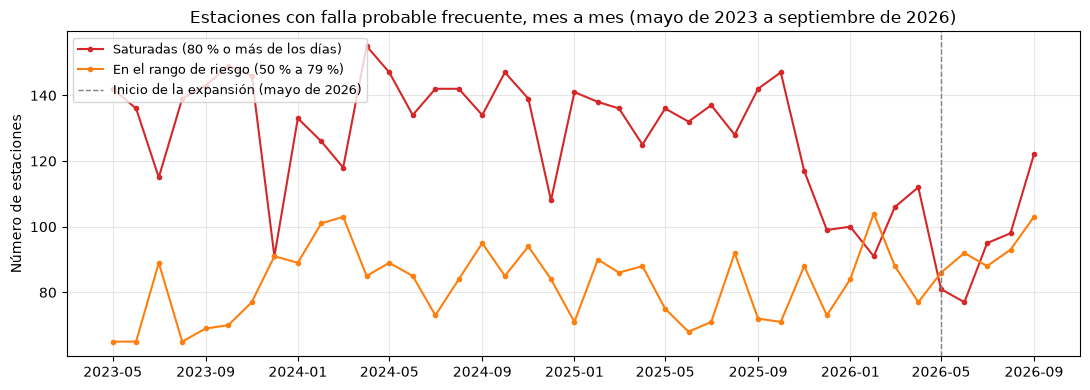

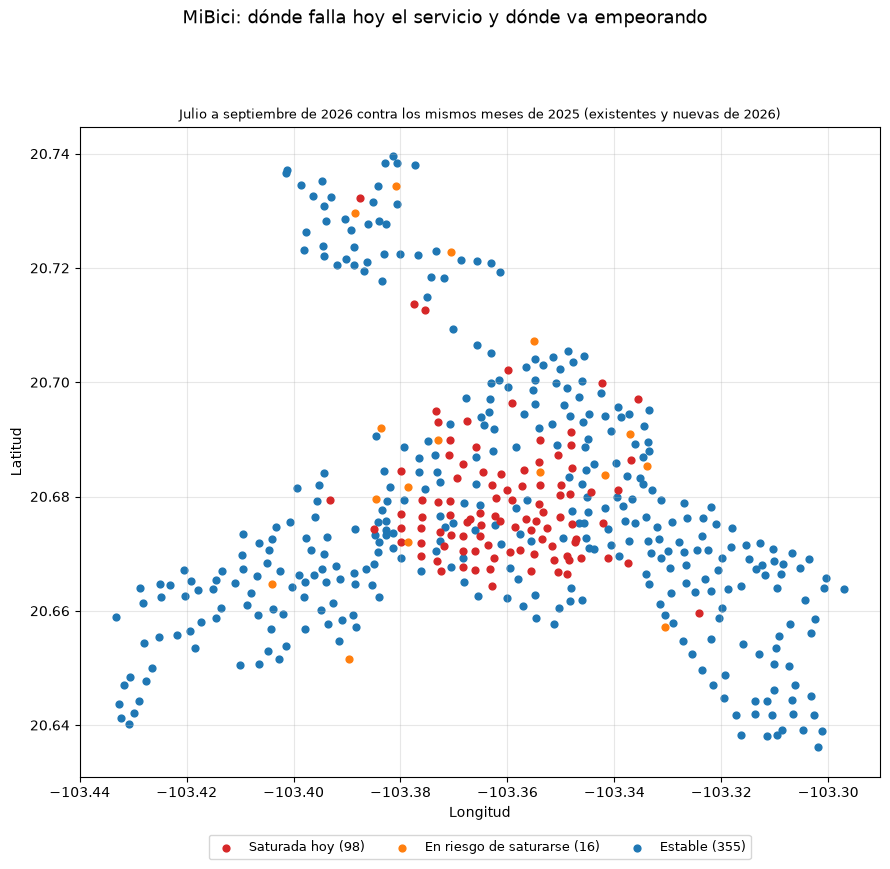

Estaciones por categoría (jul–sep 2026)


,Existentes,Nuevas 2026,Total
categoria,,,
Saturada hoy,96,2,98
En riesgo de saturarse,9,7,16
Estable,266,89,355
Total,371,98,469



Las 15 estaciones saturadas hoy más críticas (más días con falla en 2026)


,Estación,Anclajes,Días con falla jul–sep 2025 (%),Días con falla jul–sep 2026 (%),Cambio (puntos),Nueva 2026,Hora para actuar: sin bicicletas,Hora para actuar: sin anclajes
estacion_id,,,,,,,,
45,(GDL-043) C. Simón Bolivar / C. López Cotilla,11,99,100,+1,,desde las 15:00 (15–18 h),desde las 06:00 (06–09 h)
51,(GDL-049) Lopez Cotilla / Penitenciaría,39,98,100,+2,,desde las 06:00 (06–09 h),desde las 14:00 (14–17 h)
28,(GDL-026) C. Pedro Loza / C. Reforma,15,96,99,+3,,desde las 06:00 (06–09 h),desde las 10:00 (10–13 h)
260,(GDL-187) Av. 16 de Septiembre / C. Priscilia,15,100,99,-1,,desde las 06:00 (06–09 h),desde las 15:00 (15–18 h)
64,(GDL-062) C. Libertad / C. Moscú,15,100,99,-1,,desde las 17:00 (17–20 h),desde las 07:00 (07–10 h)
11,(GDL-009) Calz. Federalismo/ C. J. Angulo,23,98,99,+1,,desde las 07:00 (07–10 h),desde las 15:00 (15–18 h)
36,(GDL-034) C. Morelos / C. Donato Guerra,15,100,99,-1,,desde las 19:00 (19–22 h),desde las 08:00 (08–11 h)
81,(GDL-079) C. Donato Guerra /Av. La Paz,11,98,99,+1,,desde las 07:00 (07–10 h),desde las 15:00 (15–18 h)
160,(GDL-093) C. H Colegio Militar / Av. Américas,15,99,99,+0,,desde las 15:00 (15–18 h),desde las 06:00 (06–09 h)



Las 15 estaciones en riesgo de saturarse más críticas (mayor aumento contra 2025)


,Estación,Anclajes,Días con falla jul–sep 2025 (%),Días con falla jul–sep 2026 (%),Cambio (puntos),Nueva 2026,Hora para actuar: sin bicicletas,Hora para actuar: sin anclajes
estacion_id,,,,,,,,
347,(GDL-249)C. Agustín Rivera / C. Manuel Acuña,23,26,62,+36,,desde las 06:00 (06–09 h),desde las 18:00 (18–21 h)
225,(GDL-158) Av. Faro / Av. Las Rosas,15,36,61,+25,,desde las 05:00 (05–08 h),desde las 19:00 (19–22 h)
337,(GDL-245)C. Alejandrina / C. Torres Quintero,19,39,60,+21,,desde las 06:00 (06–09 h),desde las 19:00 (19–22 h)
288,(ZPN-048) Av. J. Parres Arias / Prol. López C,31,42,61,+18,,desde las 07:00 (07–10 h),desde las 12:00 (12–15 h)
135,(ZPN-041) C. 12 de Diciembre / C. Juan Diego,11,50,67,+17,,desde las 15:00 (15–18 h),desde las 06:00 (06–09 h)
294,(ZPN-054) Av. J. Parres Arias / C. Ignacio Ja,19,47,64,+17,,desde las 16:00 (16–19 h),desde las 07:00 (07–10 h)
186,(GDL-119) C. Fco Rojas González /C. Garibaldi,11,55,72,+16,,desde las 17:00 (17–20 h),desde las 08:00 (08–11 h)
229,(GDL-162) C. Rio Tuxpan / C. Salvador Lopez C,19,39,52,+13,,desde las 07:00 (07–10 h),desde las 17:00 (17–20 h)
246,(GDL-178) Salvador Quevedo/López Portillo,15,48,59,+11,,desde las 14:00 (14–17 h),desde las 06:00 (06–09 h)


In [6]:
# Objetivo: responder en una sola vista dónde falla hoy el servicio, dónde va empeorando y si las estaciones nuevas
# de 2026 se abrieron para aliviar a las saturadas. Se compara la misma temporada de dos años (julio a septiembre
# de 2025 contra julio a septiembre de 2026), con la regla de falla probable de la sección 4.
# Criterios (se imprimen al inicio):
#   - Saturada hoy: falla probable en el 80 % o más de los días de julio a septiembre de 2026.
#   - En riesgo de saturarse: falla en el 50 % al 79 % de los días en 2026 y al menos 10 puntos más que en 2025;
#     en las estaciones nuevas (sin datos de 2025) basta con fallar del 50 % al 79 % de los días en 2026.
#   - Estable: el resto.
#   - Nueva: primer viaje desde mayo de 2026; "cerca" = a 500 m o menos (unos 6 a 7 minutos caminando).
# Resultado esperado: resumen con las cifras clave, gráfica de evolución mensual de estaciones saturadas y en riesgo
# (guardada en reports/figures/), mapa con las tres categorías (guardado en reports/figures/), conteo de
# estaciones por categoría y las 15 estaciones más críticas saturadas hoy y en riesgo de saturarse.

import matplotlib.pyplot as plt
import numpy as np
from equipo52_module.config import FIGURES_DIR

INICIO_EXPANSION = pd.Timestamp("2026-05-01")
ANTES = (pd.Timestamp("2025-07-01"), pd.Timestamp("2025-10-01"))
HOY = (pd.Timestamp("2026-07-01"), pd.Timestamp("2026-10-01"))
SATURADA_HOY = 80        # % de días con falla
EN_RIESGO = (50, 80)     # % de días con falla en 2026 [mínimo, máximo)
AUMENTO_MINIMO = 10      # puntos de aumento contra 2025
DISTANCIA_CERCANA_KM = 0.5
CUANTAS_MOSTRAR = 15


def distancia_km(origen, destino):
    """Distancia en km entre cada punto de 'origen' y cada punto de 'destino' (latitud, longitud en grados)."""
    lat1, lon1 = np.radians(origen[:, [0]]), np.radians(origen[:, [1]])
    lat2, lon2 = np.radians(destino[:, 0]), np.radians(destino[:, 1])
    a = np.sin((lat2 - lat1) / 2) ** 2 + np.cos(lat1) * np.cos(lat2) * np.sin((lon2 - lon1) / 2) ** 2
    return 2 * 6371 * np.arcsin(np.sqrt(a))


def dias_con_falla(por_hora, periodo):
    """Porcentaje de días con alguna falla probable por estación, dentro de un periodo [inicio, fin)."""
    en_periodo = por_hora[(por_hora["hora_inicio"] >= periodo[0]) & (por_hora["hora_inicio"] < periodo[1])]
    falla = en_periodo["falla_sin_bicicletas"] | en_periodo["falla_sin_anclajes"]
    return falla.groupby([en_periodo["estacion_id"], en_periodo["dia"]]).any().groupby("estacion_id").mean() * 100


def hora_para_actuar(por_hora, columna_falla):
    """Para cada estación, la hora de inicio en que esa falla ocurre con más frecuencia ("—" si nunca ocurre)."""
    frecuencia = por_hora.groupby(["estacion_id", "hora"])[columna_falla].mean().unstack()
    hora = frecuencia.idxmax(axis=1)
    texto = hora.apply(lambda h: f"desde las {h:02d}:00 ({h:02d}–{(h + HORAS_ANTICIPACION) % 24:02d} h)")
    return texto.where(frecuencia.max(axis=1) > 0, "—")


def clasificar(pct_hoy, pct_antes, es_nueva):
    """Asigna la categoría de una estación según los criterios de esta celda."""
    if pct_hoy >= SATURADA_HOY:
        return "Saturada hoy"
    if EN_RIESGO[0] <= pct_hoy < EN_RIESGO[1] and (es_nueva or pct_hoy - pct_antes >= AUMENTO_MINIMO):
        return "En riesgo de saturarse"
    return "Estable"


# Datos por estación
ficha = nomenclatura.set_index("id")
primer_viaje = flujo_por_hora.groupby("estacion_id")["hora_inicio"].min()
nuevas = primer_viaje[primer_viaje >= INICIO_EXPANSION].index
estaciones = pd.DataFrame({"antes": dias_con_falla(por_hora, ANTES), "hoy": dias_con_falla(por_hora, HOY)})
estaciones = estaciones.dropna(subset=["hoy"])                     # solo las que operaron en jul–sep 2026
estaciones["nueva"] = estaciones.index.isin(nuevas)
estaciones["categoria"] = [clasificar(hoy, antes, nueva) for hoy, antes, nueva
                           in zip(estaciones["hoy"], estaciones["antes"], estaciones["nueva"])]
existentes = estaciones[~estaciones["nueva"]].dropna(subset=["antes"])

# ¿Se abrieron las nuevas junto a las que ya estaban saturadas en 2025?
saturada_2025 = existentes["antes"] >= SATURADA_HOY
nueva_cerca = pd.Series(distancia_km(ficha.loc[existentes.index, ["latitude", "longitude"]].values,
                                     ficha.loc[nuevas, ["latitude", "longitude"]].values).min(axis=1)
                        <= DISTANCIA_CERCANA_KM, index=existentes.index)
cambio = (existentes["hoy"] - existentes["antes"]).groupby(nueva_cerca[saturada_2025]).mean()

print("CRITERIOS")
print(f"  · Saturada hoy: falla probable en el {SATURADA_HOY} % o más de los días de jul–sep 2026")
print(f"  · En riesgo de saturarse: falla en el {EN_RIESGO[0]} % al {EN_RIESGO[1] - 1} % de los días en 2026 "
      f"y al menos {AUMENTO_MINIMO} puntos más que en jul–sep 2025\n    (estaciones nuevas, sin datos de 2025: basta con fallar del {EN_RIESGO[0]} % al {EN_RIESGO[1] - 1} % de los días en 2026)")
print(f"  · Nueva: primer viaje desde {INICIO_EXPANSION:%d/%m/%Y}; cerca = a {DISTANCIA_CERCANA_KM * 1000:.0f} m o menos\n")
print("RESUMEN")
print(f"  · Estaciones nuevas analizadas: {len(nuevas)}")
print(f"  · Saturadas en 2025 con una nueva cerca: {nueva_cerca[saturada_2025].mean():.0%} "
      f"· no saturadas con una nueva cerca: {nueva_cerca[~saturada_2025].mean():.0%}")
print(f"  · Cambio en días con falla de las saturadas de 2025 (2026 − 2025): con una nueva cerca {cambio.get(True, np.nan):+.1f} "
      f"puntos · sin una nueva cerca {cambio.get(False, np.nan):+.1f} puntos")

# Evolución mes a mes: cuántas estaciones estuvieron saturadas o en el rango de riesgo cada mes
falla_dia = (por_hora["falla_sin_bicicletas"] | por_hora["falla_sin_anclajes"]).groupby(
    [por_hora["estacion_id"], por_hora["dia"]]).any().reset_index(name="falla")
falla_dia["mes"] = falla_dia["dia"].dt.to_period("M").dt.to_timestamp()
pct_mes = falla_dia.groupby(["estacion_id", "mes"])["falla"].mean() * 100
por_mes = pd.DataFrame({
    "Saturadas (80 % o más de los días)": (pct_mes >= SATURADA_HOY).groupby("mes").sum(),
    "En el rango de riesgo (50 % a 79 %)": pct_mes.between(EN_RIESGO[0], EN_RIESGO[1], inclusive="left").groupby("mes").sum(),
})
fig, ax = plt.subplots(figsize=(11, 4))
ax.plot(por_mes.index, por_mes.iloc[:, 0], marker="o", markersize=3, color="tab:red", label=por_mes.columns[0])
ax.plot(por_mes.index, por_mes.iloc[:, 1], marker="o", markersize=3, color="tab:orange", label=por_mes.columns[1])
ax.axvline(INICIO_EXPANSION, color="grey", linestyle="--", linewidth=1, label="Inicio de la expansión (mayo de 2026)")
ax.set_title("Estaciones con falla probable frecuente, mes a mes (mayo de 2023 a septiembre de 2026)")
ax.set_ylabel("Número de estaciones")
ax.legend(loc="upper left", fontsize=9)
ax.grid(alpha=0.3)
fig.tight_layout()
fig.savefig(FIGURES_DIR / "p2_tendencia_saturacion.png", dpi=150)
plt.show()

# Mapa por categoría
colores = {"Saturada hoy": "tab:red", "En riesgo de saturarse": "tab:orange", "Estable": "tab:blue"}
fig, ax = plt.subplots(figsize=(9, 9))
for categoria, color in colores.items():  # las estables primero, para que las saturadas y en riesgo queden encima
    ids = estaciones[estaciones["categoria"] == categoria].index
    ax.scatter(ficha.loc[ids, "longitude"], ficha.loc[ids, "latitude"], s=24, color=color,
               label=f"{categoria} ({len(ids)})", zorder={"Estable": 1, "En riesgo de saturarse": 3, "Saturada hoy": 2}[categoria])
ax.set_aspect(1 / np.cos(np.radians(ficha["latitude"].mean())))
fig.suptitle("MiBici: dónde falla hoy el servicio y dónde va empeorando", fontsize=13)
ax.set_title("Julio a septiembre de 2026 contra los mismos meses de 2025 (existentes y nuevas de 2026)", fontsize=9)
ax.set_xlabel("Longitud")
ax.set_ylabel("Latitud")
ax.legend(loc="upper center", bbox_to_anchor=(0.5, -0.08), ncol=3, fontsize=9)
ax.grid(alpha=0.3)
fig.tight_layout()
fig.savefig(FIGURES_DIR / "p2_mapa_saturacion.png", dpi=150, bbox_inches="tight")
plt.show()

# Tablas
print("Estaciones por categoría (jul–sep 2026)")
display(pd.crosstab(estaciones["categoria"], estaciones["nueva"].map({False: "Existentes", True: "Nuevas 2026"}),
                    margins=True, margins_name="Total").reindex(list(colores) + ["Total"]).rename_axis(None, axis=1))

lista = pd.DataFrame({
    "Estación": ficha.loc[estaciones.index, "name"],
    "Anclajes": capacidad.reindex(estaciones.index),
    "Días con falla jul–sep 2025 (%)": estaciones["antes"].map(lambda x: "— (nueva)" if pd.isna(x) else f"{x:.0f}"),
    "Días con falla jul–sep 2026 (%)": estaciones["hoy"].round(0).astype(int),
    "Cambio (puntos)": (estaciones["hoy"] - estaciones["antes"]).round(0),
    "Nueva 2026": estaciones["nueva"].map({True: "Sí", False: ""}),
})
por_hora_hoy = por_hora[(por_hora["hora_inicio"] >= HOY[0]) & (por_hora["hora_inicio"] < HOY[1])]
lista["Hora para actuar: sin bicicletas"] = hora_para_actuar(por_hora_hoy, "falla_sin_bicicletas")
lista["Hora para actuar: sin anclajes"] = hora_para_actuar(por_hora_hoy, "falla_sin_anclajes")
print(f"\nLas {CUANTAS_MOSTRAR} estaciones saturadas hoy más críticas (más días con falla en 2026)")
display(lista[estaciones["categoria"] == "Saturada hoy"]
        .sort_values("Días con falla jul–sep 2026 (%)", ascending=False).head(CUANTAS_MOSTRAR)
        .assign(**{"Cambio (puntos)": lambda tabla: tabla["Cambio (puntos)"].map(lambda x: "—" if pd.isna(x) else f"{x:+.0f}")}))
print(f"\nLas {CUANTAS_MOSTRAR} estaciones en riesgo de saturarse más críticas (mayor aumento contra 2025)")
(lista[estaciones["categoria"] == "En riesgo de saturarse"]
 .sort_values(["Cambio (puntos)", "Días con falla jul–sep 2026 (%)"], ascending=False, na_position="last")
 .head(CUANTAS_MOSTRAR)
 .assign(**{"Cambio (puntos)": lambda tabla: tabla["Cambio (puntos)"].map(lambda x: "—" if pd.isna(x) else f"{x:+.0f}")}))

### Conclusiones: dónde falla hoy el servicio, cuándo actuar y cómo ha evolucionado

**Hoy (julio a septiembre de 2026):**
- **98 estaciones están saturadas** (falla probable en el 80 % de los días o más): 96 existentes y 2 nuevas. La mayoría de las 15 más críticas tiene solo **11 o 15 anclajes** y falla prácticamente todos los días.
- **16 estaciones están en riesgo de saturarse:** 9 existentes que empeoraron al menos 10 puntos contra 2025 (por ejemplo, GDL-249 pasó de 26 % a 62 % de días con falla) y 7 nuevas que en sus primeros meses ya fallan del 53 % al 76 % de los días.
- **La hora para actuar** muestra el patrón de ida y vuelta al trabajo: las estaciones se vacían o se llenan sobre todo entre las 5 y las 10 h, y entre las 13 y las 22 h, con horarios distintos en cada estación.

**Cómo ha evolucionado (gráfica mes a mes):**
- De mayo de 2023 a octubre de 2025 hubo entre unas 115 y 155 estaciones saturadas cada mes, con caídas en diciembre.
- Entre noviembre de 2025 y junio de 2026 el número bajó hasta 77, y de julio a septiembre de 2026 volvió a subir hasta 122. Los datos no muestran la causa de esa baja y su recuperación.

**Estaciones nuevas:**
- Se ubicaron principalmente en la periferia (mapa), no junto a las saturadas: el 30 % de las saturadas de 2025 tiene una estación nueva a 500 m o menos, contra 32 % de las no saturadas.
- Las saturadas con una nueva cerca no mejoraron más que las demás (−5.7 contra −6.9 puntos en días con falla).
- En el mapa, las saturadas se concentran en el centro y las estaciones en riesgo aparecen sobre todo alrededor de ese núcleo y al norte.

**Implicaciones:**
1. **Para la operación:** las saturadas de pocos anclajes son candidatas a **ampliar su capacidad**; las demás requieren **traslados programados** en su hora para actuar; las que están en riesgo deben **vigilarse** antes de que se saturen.
2. **Para el modelo de una estación con riesgo de saturación (p2):** la ubicación de la estación, la hora del día y el día de la semana son variables candidatas para `features.py`; y como la saturación cambia mucho de un mes a otro, el periodo de evaluación debe interpretarse con cuidado.
3. **Límites:** es *falla probable* según la regla de la sección 4; solo hay tres meses de datos después de la expansión; y 500 m es un supuesto de distancia a pie.